# Hot Under El Niño? — Week 1: *Why has Greater Nairobi been so hot, and is El Niño behind it?*

**Author:** Fides Njeri Njuguna
**Area:** Greater Nairobi — Nairobi CBD, Kiambu, Thika, Kitengela, Ongata Rongai and Ngong

### The question, and how we "prove" anything

People are asking: *"They said El Niño, so why is it so hot?"* We want to show, with data, **why** it's been hot and **whether El Niño has anything to do with it**.

Think of it like a detective case. First we confirm there *is* a case (has it really been hotter?). Then we line up the **suspects** and check each one against the evidence:

| Suspect | The idea, in plain words | How we test it |
|---|---|---|
| **1. Late rains and clear skies** | No clouds means more sunshine reaching the ground; dry soil heats up faster. If the short rains are late, the hot dry spell lasts longer. | Rain, rain-onset dates and sunshine (solar energy) vs normal |
| **2. El Niño** | A warm Pacific Ocean changes weather around the world. | Measure Pacific sea temperature for every year since 1991 and check: are Nairobi's Sep–Oct temperatures higher in El Niño years? |
| **3. The Indian Ocean Dipole (IOD)** | El Niño's "partner" in our own ocean. For East Africa, the Indian Ocean often matters *more* than the Pacific for the short rains. | Same test, with the Indian Ocean |
| **4. Long-term warming** | The whole world is slowly getting warmer, so every year starts from a higher "floor". | Is there a steady upward trend since 1991? |
| *(Week 2)* **5. Concrete and missing trees** | Roofs and tarmac trap heat; some estates are much hotter than others. | Landsat maps, next week |

### An honest word about "prove"

With 35 years of data we can show which suspects **line up with the evidence** and roughly **how much** each one contributes. That's strong, publishable evidence. What we can't do is a full laboratory-style proof: weather has many causes at once, and 35 seasons is a small sample. So the notebook uses careful wording: *"a clear link"*, *"a weak hint"*, or *"no clear link"*, based on standard statistical tests. That carefulness is what makes people trust your findings.

### Where the data comes from

| Data | What it is | Used for |
|---|---|---|
| **ERA5 / ERA5-Land** (via Open-Meteo) | Weather records rebuilt by a model from every observation available, about 5 days behind today | Air temperature, rain, sunshine at each town |
| **VIIRS** (Earth Engine) | Daily satellite readings of ground temperature at ~1:30 pm, 1 km detail | How hot the ground got, per town |
| **NOAA OISST** (Earth Engine) | Daily sea surface temperature from satellites, ships and buoys | Measuring El Niño and the Indian Ocean Dipole ourselves |
| **CHIRPS** (Earth Engine) | Rainfall from satellites corrected with rain gauges | Double-checking our rain dates |

*Why Open-Meteo and not Earth Engine for ERA5?* The Earth Engine copies of ERA5 and CHIRPS run months behind, so they don't have this September–October yet. Open-Meteo serves the same ERA5 only about 5 days late.

### Words you'll see a lot

* **Baseline / "normal":** the average for the same dates over **1991–2020**, the official 30-year period weather agencies use. Nobody can say you picked years to suit your story.
* **Anomaly:** how far something is from normal. "+1.5 °C" means 1.5 degrees hotter than usual for those dates.
* **Correlation / link:** whether two things tend to go up and down together. On its own it doesn't prove cause. But when there's also a known physical reason (sunshine heats the ground), it becomes strong evidence.
* **p-value:** roughly, *"how likely is a pattern this strong to appear by pure chance?"* Below 0.05 (5%) we call it a **clear link**; 0.05–0.10 a **weak hint**; above that, **no clear link**.

---
## Part 0 — Set up

### Step 0.1: Load the tools

**What:** bring in the Python libraries we need.
**Why:** each does one job:
* `pandas` handles tables (Excel inside Python);
* `matplotlib` draws charts;
* `requests` downloads data from the web;
* `statsmodels` runs the statistical tests;
* `ee` and `geemap` talk to Google Earth Engine and draw maps.

In [49]:
import time
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
import statsmodels.api as sm

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
print("Tools loaded. Outputs will be saved in:", OUT.resolve())

Tools loaded. Outputs will be saved in: E:\nairobi-heat-elnino\outputs


### Step 0.2: Settings you can change

**What:** every choice in one place: the towns, the baseline years, the El Niño years to compare, chart colours.
**Why:** if someone asks *"what about Ruiru?"* or *"what if you used another baseline?"*, you change one line here and re-run. It also documents your method.

**You must change `GEE_PROJECT`** to your own Earth Engine Cloud project ID.

**To add a town**, add one line to `TOWNS` with its name, latitude and longitude (right-click the spot in Google Maps to copy them).

In [50]:
GEE_PROJECT = "climate-risk-analysis-kenya"   

# Greater Nairobi: the towns we study (name: (latitude, longitude))
TOWNS = {
    "Nairobi CBD":   (-1.2864, 36.8172),
    "Kiambu":        (-1.1714, 36.8356),
    "Thika":         (-1.0333, 37.0693),
    "Kitengela":     (-1.4743, 36.9612),
    "Ongata Rongai": (-1.3963, 36.7442),
    "Ngong":         (-1.3550, 36.6650),
}
TOWN_BUFFER_M = 4000          # satellite readings: average over 4 km around each town centre

THIS_YEAR = 2026
BASELINE = (1991, 2020)            # official 30-year "normal"
ELNINO_YEARS = [1997, 2015, 2023]  # past strong El Niño years to compare against
FIRST_YEAR = 1991

SEASON_START, SEASON_END = "08-01", "11-30"   # the part of the year we chart
FOCUS_START = "09-01"                         # "this season" = 1 Sep to the latest available day

# Chart colours (checked for colour-blind safety)
COL_2026 = "#eb6834"                                              # orange: this year
COL_ELNINO = {1997: "#2a78d6", 2015: "#1baf7a", 2023: "#6250d6"}  # blue, aqua, violet
COL_NORMAL, COL_BAND, COL_OTHER = "#52514e", "#d9d8d4", "#c3c2bd"

### Step 0.3: Connect to Earth Engine

**What:** log in to Google Earth Engine from Python.
**Why:** Earth Engine stores the satellite archives (MODIS, ocean temperatures, CHIRPS) and does the heavy calculations on Google's computers, so your laptop never downloads terabytes.

The first time, a browser window asks you to sign in. After that it remembers you.

In [51]:
import ee
import geemap

try:
    ee.Initialize(project=GEE_PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT)
print("Earth Engine is connected.")

Earth Engine is connected.


### Step 0.4: Draw the study area

**What:** build the study area as **Nairobi County plus a 4 km circle around each surrounding town**, then show it on a map.
**Why:**
* The circles tell the satellite steps *exactly which ground* to average for each town.
* Why not whole counties? Kajiado County alone stretches all the way to the Tanzania border, mostly open rangeland. Averaging that in would drown out Kitengela and Ngong.
* Looking at the map is your sanity check: if a circle isn't sitting on the town, fix its coordinates before going further.

In [52]:
nairobi_county = (ee.FeatureCollection("FAO/GAUL/2015/level1")
                  .filter(ee.Filter.eq("ADM0_NAME", "Kenya"))
                  .filter(ee.Filter.eq("ADM1_NAME", "Nairobi")))
assert nairobi_county.size().getInfo() == 1, "Nairobi boundary not found in FAO GAUL — check the names."

town_fc = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([lon, lat]).buffer(TOWN_BUFFER_M), {"name": name})
    for name, (lat, lon) in TOWNS.items()])

metro_geom = nairobi_county.geometry().union(town_fc.geometry(), maxError=100)
metro_fc = ee.FeatureCollection([ee.Feature(metro_geom, {"name": "Greater Nairobi"})])
areas_fc = town_fc.merge(metro_fc)          # each town + the whole study area, all in one list

print(f"Study area: about {metro_geom.area(maxError=100).divide(1e6).getInfo():,.0f} km²")
m = geemap.Map(center=[-1.28, 36.85], zoom=10)
m.addLayer(metro_fc, {"color": "grey"}, "Greater Nairobi study area")
m.addLayer(town_fc, {"color": "orange"}, "Town circles (4 km)")
m

Study area: about 935 km²


Map(center=[-1.28, 36.85], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

---
## Part 1 — Is there a case? Has Greater Nairobi really been hotter?

### Step 1.1: Download 35+ years of daily weather for every town

**What:** for each town, download every day since 1991:
* **daily maximum temperature**, from **ERA5-Land** (10 km squares, adjusted for altitude),
* **daily rainfall** and **daily solar energy** (sunshine reaching the ground), from **ERA5**.

**Why these choices?**
* **Daily maximum** matches "it's so hot this afternoon".
* **ERA5-Land's** finer squares and altitude adjustment matter here: Ngong sits around 2,000 m and Thika around 1,500 m, and higher places are cooler.
* **Solar energy** is the evidence for Suspect 1. If skies have been clearer than normal, it will show up here.
* We fix the model names so every year comes from the same source. Mixing sources would make old and new years not comparable.

**About the waiting time:** Open-Meteo is free but limits how much you can download per minute. The code pauses between downloads and waits politely if told to slow down. The first run takes several minutes. Everything is then saved to `outputs/`, so later runs on the same day are instant.

In [53]:
API = "https://archive-api.open-meteo.com/v1/archive"

def fetch_chunk(lat, lon, start, end, model, variables):
    # One download from Open-Meteo, retrying politely if we hit the speed limit.
    params = {"latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
              "daily": ",".join(variables), "models": model, "timezone": "Africa/Nairobi"}
    for attempt in range(5):
        r = requests.get(API, params=params, timeout=180)
        if r.status_code == 429:                  # "too many requests": wait a minute and try again
            print("  (speed limit reached, waiting 65 s)")
            time.sleep(65)
            continue
        r.raise_for_status()
        d = pd.DataFrame(r.json()["daily"]).rename(columns={"time": "date"})
        d["date"] = pd.to_datetime(d["date"])
        return d
    raise RuntimeError("Open-Meteo kept refusing. Try again in an hour.")


def get_town(name, lat, lon, first_year, end):
    parts_t, parts_r = [], []
    for y0 in range(first_year, end.year + 1, 10):
        s, e = dt.date(y0, 1, 1), min(dt.date(y0 + 9, 12, 31), end)
        parts_t.append(fetch_chunk(lat, lon, s.isoformat(), e.isoformat(), "era5_land", ["temperature_2m_max"]))
        time.sleep(6)
        parts_r.append(fetch_chunk(lat, lon, s.isoformat(), e.isoformat(), "era5",
                                   ["precipitation_sum", "shortwave_radiation_sum"]))
        time.sleep(6)
    t = pd.concat(parts_t).rename(columns={"temperature_2m_max": "tmax"})
    r = pd.concat(parts_r).rename(columns={"precipitation_sum": "rain", "shortwave_radiation_sum": "sun"})
    d = t.merge(r, on="date", how="outer")
    d["town"] = name
    return d


def get_all_towns(cache=OUT / "era5_greater_nairobi_daily.csv"):
    if cache.exists() and dt.date.fromtimestamp(cache.stat().st_mtime) == dt.date.today():
        print("Using the copy downloaded earlier today.")
        return pd.read_csv(cache, parse_dates=["date"])
    end = dt.date.today() - dt.timedelta(days=5)          # ERA5 runs about 5 days behind
    frames = []
    for name, (lat, lon) in TOWNS.items():
        print(f"Downloading {name} ...")
        frames.append(get_town(name, lat, lon, FIRST_YEAR, end))
    d = pd.concat(frames, ignore_index=True)
    d.to_csv(cache, index=False)
    return d


towns_daily = get_all_towns()
# Drop the last few days if they're not filled in yet for every variable
towns_daily = towns_daily.dropna(subset=["tmax", "rain", "sun"])
LAST_DATE = towns_daily.groupby("town")["date"].max().min()
print(f"{len(towns_daily):,} town-days, up to {LAST_DATE:%d %b %Y}")
towns_daily.groupby("town")[["tmax", "rain", "sun"]].mean().round(1)

Using the copy downloaded earlier today.
78,450 town-days, up to 18 Oct 2026


,tmax,rain,sun
town,,,
Kiambu,23.6,1.6,19.8
Kitengela,24.2,1.7,19.8
Nairobi CBD,24.3,1.6,19.8
Ngong,23.4,1.6,19.8
Ongata Rongai,24.6,1.4,20.0
Thika,24.2,2.4,19.5


### Step 1.2: Make one "Greater Nairobi" series and prepare the tables

**What:**
1. Average the six towns day by day into one **Greater Nairobi** series.
2. Add helper columns:
   * `year` and `md` (month-day, e.g. `09-15`) to line up the same date across years;
   * `plotdate`, the same date placed in one dummy year so many years overlay on one chart;
   * a **7-day running average** of temperature and sunshine.

**Why the running average?** Single days jump around: one cloudy day drags the number down. Averaging each day with the 3 days on either side shows the trend you actually feel over a week.

In [54]:
def add_calendar_columns(df, smooth_cols=("tmax", "sun")):
    df = df.sort_values("date").reset_index(drop=True)
    df["year"] = df["date"].dt.year
    df["md"] = df["date"].dt.strftime("%m-%d")
    df["plotdate"] = pd.to_datetime("2000-" + df["md"])   # 2000 is a leap year, so 29 Feb has a home
    for c in smooth_cols:
        df[c + "7"] = df[c].rolling(7, center=True, min_periods=4).mean()
    return df

metro = (towns_daily[towns_daily.date <= LAST_DATE]
         .groupby("date")[["tmax", "rain", "sun"]].mean().reset_index())
metro = add_calendar_columns(metro)
season = metro[(metro.md >= SEASON_START) & (metro.md <= SEASON_END)].copy()
focus_end_md = LAST_DATE.strftime("%m-%d")
print(f"Greater Nairobi series: {metro.date.min():%Y} to {LAST_DATE:%d %b %Y}")

Greater Nairobi series: 1991 to 18 Oct 2026


### Step 1.3: What does "normal" look like for each date?

**What:** for each calendar day, take the 30 baseline years and work out:
* the **average** (the "normal" line),
* the **10th to 90th percentile** range, the band that 8 out of 10 normal years fall inside.

**Why the band?** Weather always wobbles. Being slightly above average means nothing. Being *above the band* means "hotter than 9 in 10 normal years", and that's the honest line between "a bit warm" and "genuinely unusual".

In [55]:
def climatology(df, value_col, years=BASELINE):
    base = df[df["year"].between(*years)]
    clim = base.groupby("md")[value_col].agg(
        normal="mean", p10=lambda s: s.quantile(0.10), p90=lambda s: s.quantile(0.90)).reset_index()
    clim["plotdate"] = pd.to_datetime("2000-" + clim["md"])
    return clim

tmax_clim = climatology(season, "tmax7")
sun_clim = climatology(season, "sun7")

### Step 1.4: The headline chart

**What:** the normal band (grey), the normal line (dashed), past El Niño years (thin coloured lines), and 2026 (thick orange).

**How to read it:**
* Orange **above the grey band** → hotter than 9 in 10 normal years for those dates.
* Orange **inside the band** → within the normal ups and downs.
* If the thin El Niño lines *also* ran hot in September–October, then "hot before the rains in an El Niño year" is a pattern, not a contradiction.

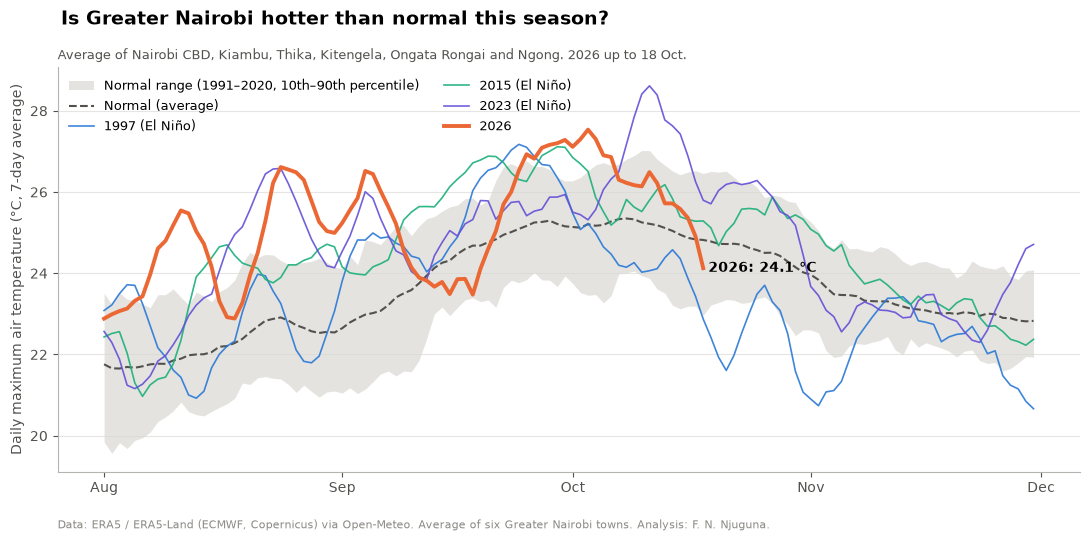

In [56]:
CREDIT_ERA5 = "Data: ERA5 / ERA5-Land (ECMWF, Copernicus) via Open-Meteo. Average of six Greater Nairobi towns. Analysis: F. N. Njuguna."

def style_axes(ax, dates=True):
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4af")
    ax.tick_params(colors="#52514e")
    if dates:
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))


def titles(fig, ax, title, subtitle, credit=None, credit_y=-0.14):
    fig.suptitle(title, x=0.06, ha="left", fontsize=14, fontweight="bold")
    ax.set_title(subtitle, loc="left", fontsize=9.5, color="#52514e")
    if credit:
        ax.text(0, credit_y, credit, transform=ax.transAxes, fontsize=8, color="#8a8984")


def plot_seasonal(df, clim, col, ylabel, title, subtitle, credit=CREDIT_ERA5, onsets=None, fname=None, unit=""):
    fig, ax = plt.subplots(figsize=(11, 5.5))
    ax.fill_between(clim.plotdate, clim.p10, clim.p90, color=COL_BAND, alpha=0.7, lw=0,
                    label=f"Normal range ({BASELINE[0]}–{BASELINE[1]}, 10th–90th percentile)")
    ax.plot(clim.plotdate, clim.normal, color=COL_NORMAL, lw=1.5, ls="--", label="Normal (average)")
    for y, c in COL_ELNINO.items():
        d = df[df.year == y]
        ax.plot(d.plotdate, d[col], color=c, lw=1.2, alpha=0.9, label=f"{y} (El Niño)")
    d = df[df.year == THIS_YEAR].dropna(subset=[col])
    ax.plot(d.plotdate, d[col], color=COL_2026, lw=2.8, label=str(THIS_YEAR))
    if len(d):
        last = d.iloc[-1]
        ax.annotate(f" {THIS_YEAR}: {last[col]:.1f}{unit}", (last.plotdate, last[col]),
                    fontsize=10, fontweight="bold", va="center")
    if onsets:
        top = ax.get_ylim()[1]
        for label, (date_, color, ls) in onsets.items():
            if pd.notna(date_):
                x = pd.to_datetime("2000-" + date_.strftime("%m-%d"))
                ax.axvline(x, color=color, ls=ls, lw=1.2)
                ax.text(x, top, " " + label, rotation=90, va="top", ha="left", fontsize=8.5, color="#52514e")
    style_axes(ax)
    ax.set_ylabel(ylabel, color="#52514e")
    titles(fig, ax, title, subtitle, credit)
    ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
    fig.tight_layout()
    if fname:
        fig.savefig(OUT / fname, dpi=200, bbox_inches="tight")
    return fig, ax

plot_seasonal(season, tmax_clim, "tmax7", "Daily maximum air temperature (°C, 7-day average)",
              "Is Greater Nairobi hotter than normal this season?",
              f"Average of Nairobi CBD, Kiambu, Thika, Kitengela, Ongata Rongai and Ngong. {THIS_YEAR} up to {LAST_DATE:%d %b}.",
              fname="chart1_air_temperature.png", unit=" °C")
plt.show()

### Step 1.5: Put a number on it, for Greater Nairobi and for each town

**What:** for every year, average the daily maximum over **exactly the same dates** (1 September to the latest day we have for 2026). Then:
* subtract the normal to get each year's **anomaly**,
* **rank** the years (1 = hottest),
* do the same for each town separately.

**Why the same dates every year?** 2026 only runs to mid/late October. November is usually cooler once the rains are in, so comparing against full seasons would be unfair. Same window for everyone keeps it fair.

**Why each town?** People in Kitengela and Thika will ask "what about us?". It also hints at Week 2: if some towns are running hotter than others, that points to local causes like land cover.

In [57]:
def yearly_window_mean(df, col, start_md=FOCUS_START, end_md=None):
    end_md = end_md or focus_end_md
    sel = df[(df.md >= start_md) & (df.md <= end_md)]
    return sel.groupby("year")[col].mean()


def anomaly_table(df, col="tmax"):
    y = yearly_window_mean(df, col)
    a = (y - y.loc[BASELINE[0]:BASELINE[1]].mean()).rename("anomaly").to_frame()
    a["value"] = y
    a["rank_hottest"] = a["anomaly"].rank(ascending=False).astype(int)
    return a

anom = anomaly_table(metro)
n_years = len(anom)
print(f"Window: 1 Sep – {LAST_DATE:%d %b}, every year {anom.index.min()}–{anom.index.max()} ({n_years} years)\n")
print(f"GREATER NAIROBI {THIS_YEAR}: {anom.loc[THIS_YEAR,'value']:.1f} °C, "
      f"{anom.loc[THIS_YEAR,'anomaly']:+.2f} °C vs normal, rank {anom.loc[THIS_YEAR,'rank_hottest']} of {n_years} (1 = hottest)")
for y in ELNINO_YEARS:
    print(f"   {y} (El Niño): {anom.loc[y,'anomaly']:+.2f} °C, rank {anom.loc[y,'rank_hottest']}")

town_rows = []
for name, d in towns_daily[towns_daily.date <= LAST_DATE].groupby("town"):
    a = anomaly_table(add_calendar_columns(d, smooth_cols=()))
    town_rows.append({"town": name, "normal_C": a.loc[BASELINE[0]:BASELINE[1], "value"].mean(),
                      f"{THIS_YEAR}_C": a.loc[THIS_YEAR, "value"], "anomaly_C": a.loc[THIS_YEAR, "anomaly"],
                      "rank_hottest": a.loc[THIS_YEAR, "rank_hottest"]})
town_table = pd.DataFrame(town_rows).set_index("town").sort_values("anomaly_C", ascending=False).round(2)
print("\nEach town, same window:")
display(town_table)

anom.to_csv(OUT / "table_air_temp_anomaly_by_year.csv")
town_table.to_csv(OUT / "table_towns_2026.csv")

Window: 1 Sep – 18 Oct, every year 1991–2026 (36 years)

GREATER NAIROBI 2026: 25.7 °C, +1.11 °C vs normal, rank 5 of 36 (1 = hottest)
   1997 (El Niño): +0.59 °C, rank 9
   2015 (El Niño): +1.22 °C, rank 3
   2023 (El Niño): +1.30 °C, rank 1

Each town, same window:


,normal_C,2026_C,anomaly_C,rank_hottest
town,,,,
Ongata Rongai,25.04,26.72,1.67,1
Ngong,23.85,25.52,1.67,1
Nairobi CBD,24.69,25.93,1.23,2
Kiambu,23.88,24.91,1.03,4
Kitengela,24.86,25.49,0.64,6
Thika,25.00,25.45,0.44,10


### Step 1.6: Two charts from those numbers

**Chart 2, every year side by side:** one bar per year, 2026 and El Niño years coloured. Bars above zero were hotter than normal. You'll also see whether bars drift upward over time, which is the first clue for Suspect 4 (long-term warming).

**Chart 3, the towns:** how far above or below normal each town has been this season.

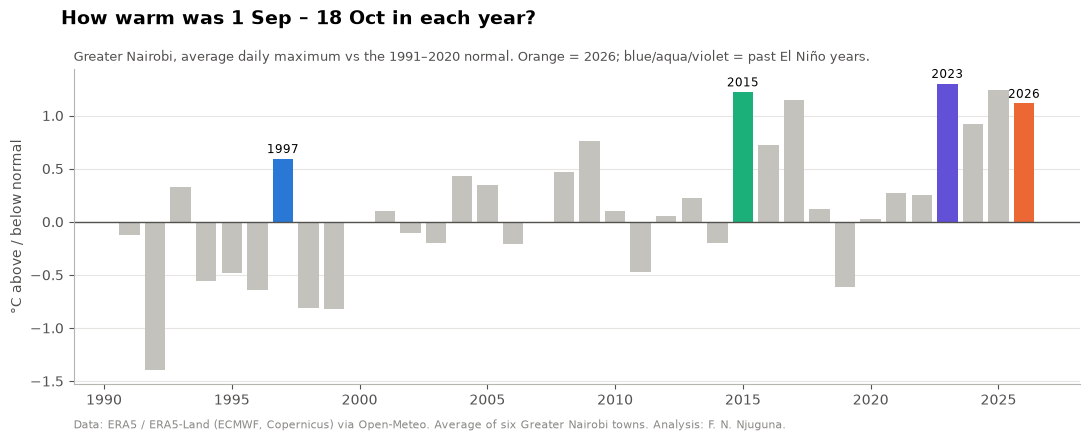

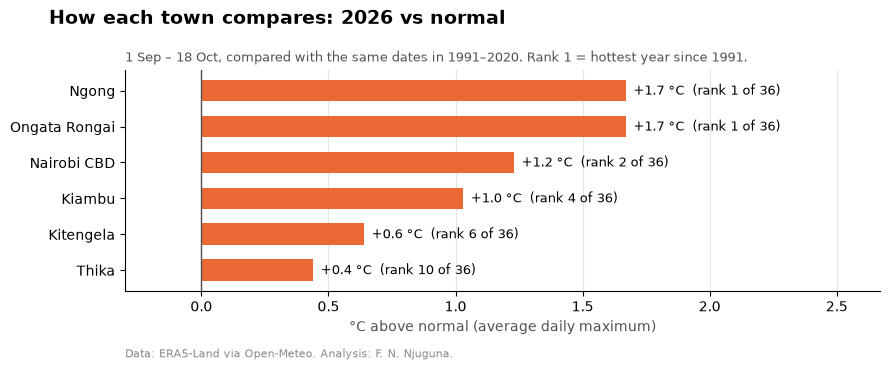

In [58]:
fig, ax = plt.subplots(figsize=(11, 4.5))
colors = [COL_2026 if y == THIS_YEAR else COL_ELNINO.get(y, COL_OTHER) for y in anom.index]
ax.bar(anom.index, anom.anomaly, color=colors, width=0.8)
ax.axhline(0, color="#52514e", lw=1)
for y in ELNINO_YEARS + [THIS_YEAR]:
    v = anom.loc[y, "anomaly"]
    ax.annotate(str(y), (y, v), xytext=(0, 4 if v >= 0 else -12), textcoords="offset points", ha="center", fontsize=8.5)
style_axes(ax, dates=False)
ax.set_ylabel("°C above / below normal", color="#52514e")
titles(fig, ax, f"How warm was 1 Sep – {LAST_DATE:%d %b} in each year?",
       f"Greater Nairobi, average daily maximum vs the {BASELINE[0]}–{BASELINE[1]} normal. Orange = {THIS_YEAR}; "
       "blue/aqua/violet = past El Niño years.", CREDIT_ERA5)
fig.tight_layout(); fig.savefig(OUT / "chart2_anomaly_by_year.png", dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
tt = town_table.sort_values("anomaly_C")
ax.barh(tt.index, tt.anomaly_C, color=COL_2026, height=0.6)
for i, (v, r) in enumerate(zip(tt.anomaly_C, tt.rank_hottest)):
    ax.text(v + (0.03 if v >= 0 else -0.03), i, f"{v:+.1f} °C  (rank {r} of {n_years})",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="#52514e", lw=1)
ax.grid(axis="x", color="#e6e5e1"); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.set_xlim(min(0, tt.anomaly_C.min()) - 0.3, tt.anomaly_C.max() + 1.0)
ax.set_xlabel("°C above normal (average daily maximum)", color="#52514e")
titles(fig, ax, f"How each town compares: {THIS_YEAR} vs normal",
       f"1 Sep – {LAST_DATE:%d %b}, compared with the same dates in {BASELINE[0]}–{BASELINE[1]}. Rank 1 = hottest year since {FIRST_YEAR}.",
       "Data: ERA5-Land via Open-Meteo. Analysis: F. N. Njuguna.", credit_y=-0.3)
fig.tight_layout(); fig.savefig(OUT / "chart3_towns.png", dpi=200, bbox_inches="tight"); plt.show()

---
## Part 2 — Suspect 1: late rains and clear skies

### Step 2.1: How much rain has fallen since 1 September?

**What:** add up the rain day by day from 1 September (a running total) for Greater Nairobi, and compare 2026 with normal and the El Niño years.
**Why a running total?** Daily rain is spiky. A running total shows at a glance whether the season is behind or ahead: flat means dry, steep means heavy rain.

Rain since 1 Sep 2026: 30 mm vs a normal 34 mm by 18 Oct (86% of normal)


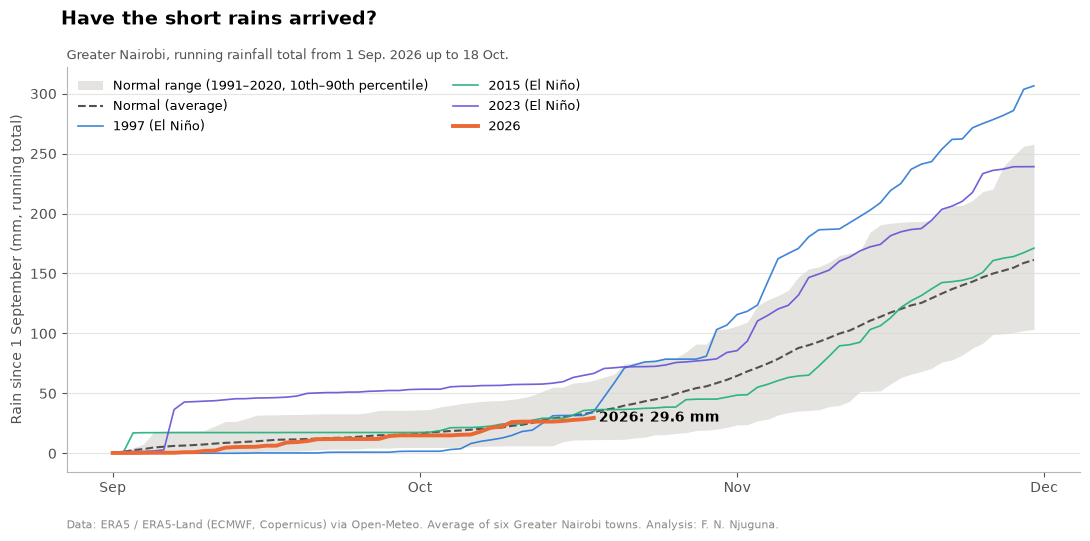

In [59]:
rainseason = metro[(metro.md >= FOCUS_START)].copy()
rainseason["rain_cum"] = rainseason.groupby("year")["rain"].cumsum()
rain_clim = climatology(rainseason, "rain_cum")
so_far = rainseason.loc[rainseason.year == THIS_YEAR, "rain_cum"].max()
normal_so_far = rain_clim.loc[rain_clim.md == focus_end_md, "normal"].iloc[0]
print(f"Rain since 1 Sep {THIS_YEAR}: {so_far:.0f} mm vs a normal {normal_so_far:.0f} mm by {LAST_DATE:%d %b} "
      f"({so_far / normal_so_far:.0%} of normal)")

rs = rainseason[rainseason.md <= SEASON_END]
plot_seasonal(rs, rain_clim[rain_clim.md <= SEASON_END], "rain_cum", "Rain since 1 September (mm, running total)",
              "Have the short rains arrived?",
              f"Greater Nairobi, running rainfall total from 1 Sep. {THIS_YEAR} up to {LAST_DATE:%d %b}.",
              fname="chart4_cumulative_rain.png", unit=" mm")
plt.show()

### Step 2.2: The day the rains *really* started, every year

**What:** apply one fixed rule to every year to find the **onset** of the short rains.

**The rule (a standard one for East African rainy seasons):**
1. From 1 September, find the first time **3 days together bring at least 20 mm**: a proper soaking, not a passing shower.
2. Check the **next 21 days**. If there's a dry spell of **7+ days in a row** (each under 1 mm), it was a *false start*, the kind where farmers plant after the first shower and the seeds dry out. Ignore it and keep looking.
3. The first wet spell that passes both checks is the onset.

**Why a fixed rule?** "When it felt like the rains started" differs from person to person. A rule gives the same answer every time, and anyone can check it.

**2026:** if the latest wet spell is under 21 days old, check 2 can't be completed yet, so it's marked **"tentative"**.

In [60]:
def longest_dry_run(rain, dry_day=1.0):
    best = run = 0
    for r in rain:
        run = run + 1 if r < dry_day else 0
        best = max(best, run)
    return best


def find_onset(daily_rain, wet_3day=20.0, dry_day=1.0, dry_spell=7, lookahead=21):
    s = daily_rain.dropna()
    three_day = s.rolling(3).sum()
    for i in range(2, len(s)):
        if three_day.iloc[i] < wet_3day:
            continue
        after = s.iloc[i + 1:i + 1 + lookahead]
        if longest_dry_run(after, dry_day) >= dry_spell:
            continue                                   # false start
        return s.index[i], ("confirmed" if len(after) == lookahead else "tentative")
    return pd.NaT, "not yet"


def onsets_by_year(df, rain_col="rain"):
    rows = []
    for y, d in df[(df.md >= FOCUS_START) & (df.md <= "12-31")].groupby("year"):
        date_, status = find_onset(d.set_index("date")[rain_col])
        rows.append({"year": y, "onset": date_, "status": status,
                     "onset_doy": date_.dayofyear if pd.notna(date_) else np.nan})
    return pd.DataFrame(rows).set_index("year")

onsets = onsets_by_year(metro)
median_doy = int(onsets.loc[BASELINE[0]:BASELINE[1], "onset_doy"].median())
median_onset = pd.Timestamp(f"{THIS_YEAR}-01-01") + pd.Timedelta(days=median_doy - 1)
print(f"Normal onset ({BASELINE[0]}–{BASELINE[1]} median): around {median_onset:%d %B}")
for y in ELNINO_YEARS + [THIS_YEAR]:
    o = onsets.loc[y]
    if pd.notna(o.onset):
        print(f"{y}: {o.onset:%d %B} [{o.status}]  ({int(o.onset_doy) - median_doy:+d} days vs normal)")
    else:
        print(f"{y}: not started by {LAST_DATE:%d %B}")
onsets.to_csv(OUT / "table_rain_onset_by_year.csv")

Normal onset (1991–2020 median): around 06 November
1997: 20 October [confirmed]  (-17 days vs normal)
2015: 11 November [confirmed]  (+5 days vs normal)
2023: 03 November [confirmed]  (-3 days vs normal)
2026: not started by 18 October


### Step 2.3: Has there been more sunshine than normal?

**What:** compare 2026's daily **solar energy reaching the ground** (MJ per m², 7-day average) with normal.
**Why:** this is the most direct test of Suspect 1. Clouds block sunlight. If skies have been clearer than usual because the rains are late, more energy hits the ground, and the ground and air heat up. If sunshine has been normal, Suspect 1 is weaker.

Solar energy 1 Sep – 18 Oct 2026: 21.2 MJ/m² per day, +0% vs normal (rank 17 of 36, 1 = sunniest)


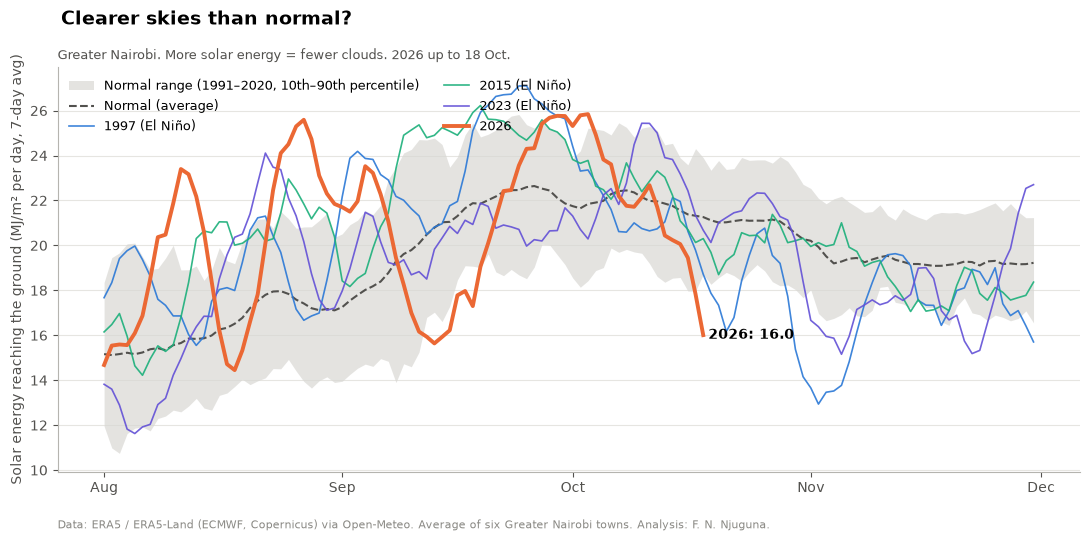

In [61]:
sun_anom = anomaly_table(metro, "sun")
print(f"Solar energy 1 Sep – {LAST_DATE:%d %b} {THIS_YEAR}: {sun_anom.loc[THIS_YEAR,'value']:.1f} MJ/m² per day, "
      f"{sun_anom.loc[THIS_YEAR,'anomaly'] / (sun_anom.loc[THIS_YEAR,'value'] - sun_anom.loc[THIS_YEAR,'anomaly']):+.0%} vs normal "
      f"(rank {sun_anom.loc[THIS_YEAR,'rank_hottest']} of {n_years}, 1 = sunniest)")
plot_seasonal(season, sun_clim, "sun7", "Solar energy reaching the ground (MJ/m² per day, 7-day avg)",
              "Clearer skies than normal?",
              f"Greater Nairobi. More solar energy = fewer clouds. {THIS_YEAR} up to {LAST_DATE:%d %b}.",
              fname="chart5_sunshine.png")
plt.show()

### Step 2.4: How much does sunshine explain the day-to-day heat?

**What:** take every day from August to November in all years. For each day, compute how far temperature was from normal and how far sunshine was from normal. Then measure how closely the two move together.

**Why:** if, across 35 years, sunnier-than-normal weeks are reliably hotter-than-normal weeks, then *"it's hot because the skies have been clear"* isn't a guess. It's a measured relationship, and we can say how many degrees of this year's heat it accounts for.

**How to read the output:**
* **"Each extra 1 MJ/m² of sunshine adds X °C"**: the strength of the effect.
* **"Explains Y% of the ups and downs"**: how much of the heat variation tracks sunshine. 50%+ is a lot for weather.

In [62]:
def daily_anomalies(df, cols):
    out = df.copy()
    for c in cols:
        normal = df[df.year.between(*BASELINE)].groupby("md")[c].mean()
        out[c + "_anom"] = out[c] - out["md"].map(normal)
    return out

sa = daily_anomalies(season, ["tmax7", "sun7"]).dropna(subset=["tmax7_anom", "sun7_anom"])
fit_days = sa[sa.year < THIS_YEAR]
X = sm.add_constant(fit_days[["sun7_anom"]])
sun_model = sm.OLS(fit_days["tmax7_anom"], X).fit()
b_sun = sun_model.params["sun7_anom"]
print(f"Each extra 1 MJ/m² of daily sunshine (7-day average) adds about {b_sun:.2f} °C to the daily maximum.")
print(f"Sunshine explains {sun_model.rsquared:.0%} of the ups and downs in heat, Aug–Nov, {FIRST_YEAR}–{THIS_YEAR - 1}.")

this = sa[(sa.year == THIS_YEAR) & (sa.md >= FOCUS_START)]
sun_part = b_sun * this["sun7_anom"].mean()
print(f"\nIn {THIS_YEAR} (1 Sep – {LAST_DATE:%d %b}): sunshine was {this['sun7_anom'].mean():+.2f} MJ/m² vs normal, "
      f"which accounts for roughly {sun_part:+.2f} °C of the {this['tmax7_anom'].mean():+.2f} °C anomaly.")

Each extra 1 MJ/m² of daily sunshine (7-day average) adds about 0.40 °C to the daily maximum.
Sunshine explains 68% of the ups and downs in heat, Aug–Nov, 1991–2025.

In 2026 (1 Sep – 18 Oct): sunshine was +0.09 MJ/m² vs normal, which accounts for roughly +0.04 °C of the +1.11 °C anomaly.


---
## Part 3 — Suspects 2, 3 and 4: El Niño, the Indian Ocean and long-term warming

### The idea, in plain words

* **El Niño** is measured by how warm the sea is in a box of the central Pacific called **Niño 3.4**. Warmer than normal = El Niño.
* The **Indian Ocean Dipole (IOD)** compares the western Indian Ocean (near Kenya) with the eastern side (near Indonesia). When our side is warmer than theirs, the IOD is **positive**, which usually means **wetter short rains in East Africa**. Strong El Niños often come with a positive IOD (1997, 2023), but not always.
* Rather than copy someone else's index, we **measure both oceans ourselves** from satellite sea temperatures in Earth Engine. It's the same method the agencies use, and it's a great skill to show.

Then we ask, year by year since 1991: **when the Pacific or Indian Ocean was warm in September–October, was Greater Nairobi hotter?** We include the **year** as a third factor, to separate the steady long-term warming from the ocean effects.

### Step 3.1: Measure the oceans for every year

**What:** for each year, average the daily sea surface temperature from 1 September to the same end date, over three boxes (Niño 3.4, the west Indian Ocean and the east Indian Ocean) plus **all tropical oceans** (20°S–20°N).
**Why the whole tropics?** It's needed for the *relative* El Niño score in Step 3.2.
**Why one year at a time, with retries?** Asking for all 36 years in one request breaks Earth Engine's free limit ("Too many concurrent aggregations").
**Why the same dates?** So the oceans and Nairobi are compared over exactly the same weeks.

In [63]:
oisst = ee.ImageCollection("NOAA/CDR/OISST/V2_1").select("sst")
boxes = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Rectangle([-170, -5, -120, 5], None, False), {"box": "nino34"}),
    ee.Feature(ee.Geometry.Rectangle([50, -10, 70, 10], None, False), {"box": "iod_west"}),
    ee.Feature(ee.Geometry.Rectangle([90, -10, 110, 0], None, False), {"box": "iod_east"}),
])
tropics = ee.Geometry.Rectangle([-179.99, -20, 179.99, 20], None, False)   # all tropical oceans
end_md = focus_end_md

def ocean_year(y):
    start = f"{y}-09-01"
    end = (pd.Timestamp(f"{y}-{end_md}") + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    img = oisst.filterDate(start, end).mean().multiply(0.01)
    fc = img.reduceRegions(boxes, ee.Reducer.mean(), 27830)
    out = {f["properties"]["box"]: f["properties"]["mean"] for f in fc.getInfo()["features"]}
    out["trop"] = img.reduceRegion(ee.Reducer.mean(), tropics, 111000, maxPixels=1e9).get("sst").getInfo()
    return out

cache = OUT / "ocean_sst_by_year.csv"
fresh = (cache.exists() and dt.date.fromtimestamp(cache.stat().st_mtime) == dt.date.today()
         and "trop" in pd.read_csv(cache, nrows=1).columns)
if fresh:
    sst_raw = pd.read_csv(cache, index_col="year")
    print("Using the ocean data saved earlier today.")
else:
    rows = []
    for y in range(FIRST_YEAR, THIS_YEAR + 1):
        for attempt in range(5):
            try:
                r = ocean_year(y)
                break
            except ee.EEException as e:
                if "Too many" in str(e) or "429" in str(e):
                    time.sleep(10 * (attempt + 1))
                    continue
                raise
        else:
            raise RuntimeError(f"Earth Engine stayed busy for {y}. Wait a few minutes and run again.")
        r["year"] = y
        rows.append(r)
        print(y, end=" ")
    sst_raw = pd.DataFrame(rows).set_index("year")
    sst_raw.to_csv(cache)

sst_raw.index = sst_raw.index.astype(int)
sst_raw.tail()

Using the ocean data saved earlier today.


,nino34,iod_west,iod_east,trop
year,,,,
2022,25.816029,27.520494,28.581142,26.839673
2023,28.261389,28.549600,27.617951,27.513183
2024,26.407449,28.357518,28.646695,27.336620
2025,26.239985,27.883059,28.898238,27.090677
2026,29.783135,28.878582,28.406087,27.838226


### Step 3.2: Turn sea temperatures into El Niño and IOD scores

**What:**
* **Relative Niño 3.4 score** = how much warmer than normal the Pacific box is, **minus** how much warmer than normal all tropical oceans are. Above about **+0.5 °C** counts as El Niño conditions.
* **IOD score** = (west box minus its normal) − (east box minus its normal). Above about **+0.4 °C** is a positive IOD.

**Why "relative"?** All tropical oceans have warmed. Measured against a fixed 30-year average (the *traditional* method), every recent year looks more like El Niño than it really is, and El Niño gets tangled up with long-term warming. In February 2026 NOAA switched to a relative index for exactly this reason. Our 2026 value (about +2.1 °C) matches NOAA's.

The table prints both versions so you can see the difference.

In [64]:
anom_sst = sst_raw - sst_raw.loc[BASELINE[0]:BASELINE[1]].mean()
ocean = pd.DataFrame(index=sst_raw.index)
ocean["nino34_traditional"] = anom_sst["nino34"]        # old method: vs the 1991–2020 average
ocean["tropics"] = anom_sst["trop"]                     # how much warmer all tropical oceans are
ocean["nino34"] = anom_sst["nino34"] - anom_sst["trop"] # RELATIVE: Pacific warmth beyond the tropics' warmth
ocean["iod"] = anom_sst["iod_west"] - anom_sst["iod_east"]

print("Year   traditional  tropics  RELATIVE El Niño   IOD")
for y in ELNINO_YEARS + [THIS_YEAR]:
    r = ocean.loc[y]
    print(f"{y}   {r.nino34_traditional:+.2f}        {r.tropics:+.2f}    {r.nino34:+.2f}             {r.iod:+.2f}")

Year   traditional  tropics  RELATIVE El Niño   IOD
1997   +1.98        +0.16    +1.82             +0.90
2015   +1.97        +0.58    +1.38             +0.84
2023   +1.57        +0.69    +0.89             +1.16
2026   +3.09        +1.01    +2.08             +0.70


### Step 3.3: The test, putting all three suspects in one model

**What:** a *multiple regression*. In plain words, it finds the best recipe of the form:

> Nairobi heat anomaly ≈ (a bit per year, for long-term warming) + (a bit per degree of El Niño) + (a bit per degree of IOD)

It works out each "bit" **at the same time**, so they don't steal credit from each other. For example, 2023 was both an El Niño year *and* a recent, warmer year. The model separates those two effects.

We fit it on **1991–2025** and leave 2026 out, so 2026 is a genuine test, not part of the answer.

**How to read the output:** for each suspect you get the size of its effect and a verdict (*clear link / weak hint / no clear link*) based on its p-value. We run the same test on the **rain onset date**, because the El Niño forecasts were about *rain*.

In [65]:
def verdict(p):
    return "a clear link" if p < 0.05 else ("a weak hint" if p < 0.10 else "no clear link")


def verdict_dir(p, coef, up="hotter", down="cooler"):
    # Same as verdict(), plus which way the link points
    v = verdict(p)
    return v if v == "no clear link" else f"{v} ({up if coef > 0 else down})"

yr = anom[["anomaly"]].join(ocean).join(onsets[["onset_doy"]])
yr["years_since_2005"] = yr.index - 2005      # centred on the middle of the baseline
fit = yr.loc[FIRST_YEAR:THIS_YEAR - 1].dropna(subset=["anomaly", "nino34", "iod"])

heat_model = sm.OLS(fit["anomaly"], sm.add_constant(fit[["years_since_2005", "nino34", "iod"]])).fit()
hp, hc = heat_model.pvalues, heat_model.params
print("HEAT (Sep–Oct daily maximum, Greater Nairobi):")
print(f"  Long-term warming: {hc['years_since_2005'] * 10:+.2f} °C per decade  → {verdict(hp['years_since_2005'])} (p = {hp['years_since_2005']:.3f})")
print(f"  El Niño:           {hc['nino34']:+.2f} °C per 1 °C of Pacific warmth → {verdict(hp['nino34'])} (p = {hp['nino34']:.3f})")
print(f"  Indian Ocean:      {hc['iod']:+.2f} °C per 1 °C of IOD           → {verdict(hp['iod'])} (p = {hp['iod']:.3f})")
print(f"  Together they explain {heat_model.rsquared:.0%} of the year-to-year differences.")

fo = fit.dropna(subset=["onset_doy"])
onset_model = sm.OLS(fo["onset_doy"], sm.add_constant(fo[["nino34", "iod"]])).fit()
op, oc = onset_model.pvalues, onset_model.params
print("\nRAIN ONSET (negative = rains start earlier):")
print(f"  El Niño:      {oc['nino34']:+.1f} days per 1 °C → {verdict(op['nino34'])} (p = {op['nino34']:.3f})")
print(f"  Indian Ocean: {oc['iod']:+.1f} days per 1 °C → {verdict(op['iod'])} (p = {op['iod']:.3f})")

yr.to_csv(OUT / "table_year_by_year_suspects.csv")

HEAT (Sep–Oct daily maximum, Greater Nairobi):
  Long-term warming: +0.50 °C per decade  → a clear link (p = 0.000)
  El Niño:           +0.54 °C per 1 °C of Pacific warmth → a clear link (p = 0.001)
  Indian Ocean:      -0.35 °C per 1 °C of IOD           → a clear link (p = 0.033)
  Together they explain 54% of the year-to-year differences.

RAIN ONSET (negative = rains start earlier):
  El Niño:      +3.0 days per 1 °C → no clear link (p = 0.633)
  Indian Ocean: -11.8 days per 1 °C → a weak hint (p = 0.091)


### Step 3.4: Picture the El Niño test

**What:** each dot is one year: how warm the Pacific was (across) against how hot Greater Nairobi was (up). El Niño years and 2026 are labelled.
**How to read it:**
* If the dots slope **upward to the right**, El Niño years tend to be hotter in Nairobi.
* A **flat cloud** means El Niño doesn't, by itself, decide Sep–Oct heat here.

Either result is a finding worth sharing.

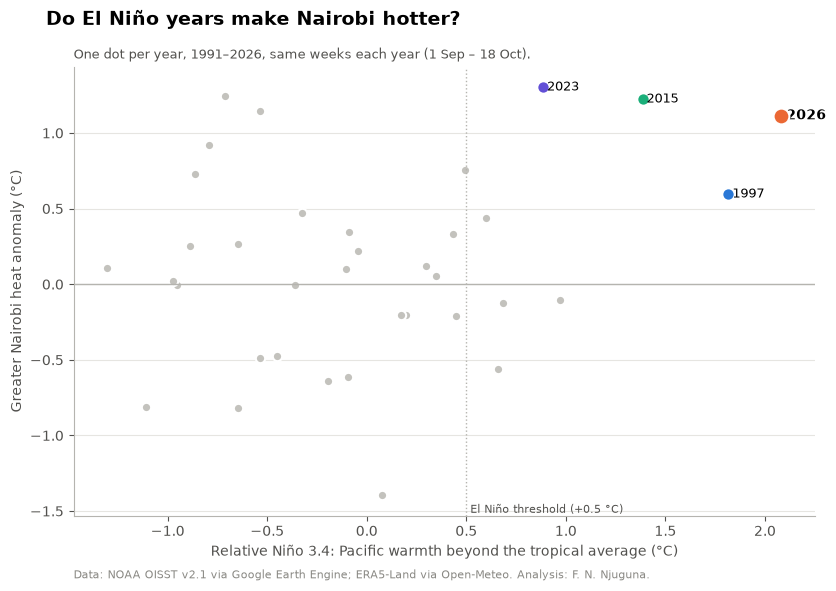

In [66]:
fig, ax = plt.subplots(figsize=(8.5, 6))
other = yr.drop(index=ELNINO_YEARS + [THIS_YEAR], errors="ignore")
ax.scatter(other.nino34, other.anomaly, s=45, color=COL_OTHER, edgecolor="white", linewidth=1.5, label="Other years")
for y, c in COL_ELNINO.items():
    ax.scatter(yr.loc[y, "nino34"], yr.loc[y, "anomaly"], s=80, color=c, edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f" {y}", (yr.loc[y, "nino34"], yr.loc[y, "anomaly"]), fontsize=9, va="center")
ax.scatter(yr.loc[THIS_YEAR, "nino34"], yr.loc[THIS_YEAR, "anomaly"], s=130, color=COL_2026,
           edgecolor="white", linewidth=1.5, zorder=4)
ax.annotate(f" {THIS_YEAR}", (yr.loc[THIS_YEAR, "nino34"], yr.loc[THIS_YEAR, "anomaly"]),
            fontsize=10, fontweight="bold", va="center")
ax.axhline(0, color="#b5b4af", lw=1); ax.axvline(0.5, color="#b5b4af", lw=1, ls=":")
ax.text(0.52, ax.get_ylim()[0], "El Niño threshold (+0.5 °C)", fontsize=8, color="#52514e", va="bottom")
style_axes(ax, dates=False)
ax.set_xlabel("Relative Niño 3.4: Pacific warmth beyond the tropical average (°C)", color="#52514e")
ax.set_ylabel("Greater Nairobi heat anomaly (°C)", color="#52514e")
titles(fig, ax, "Do El Niño years make Nairobi hotter?",
       f"One dot per year, {FIRST_YEAR}–{THIS_YEAR}, same weeks each year (1 Sep – {LAST_DATE:%d %b}).",
       "Data: NOAA OISST v2.1 via Google Earth Engine; ERA5-Land via Open-Meteo. Analysis: F. N. Njuguna.")
fig.tight_layout(); fig.savefig(OUT / "chart6_elnino_test.png", dpi=200, bbox_inches="tight"); plt.show()

### Step 3.5: Where did 2026's extra heat come from?

**What:** split 2026's heat anomaly into pieces:
* **Long-term warming:** what the trend alone predicts for 2026.
* **El Niño:** the model's El Niño effect × this year's Pacific warmth.
* **Indian Ocean:** the same for the IOD.
* **Not explained by the model:** what's left over: this season's weather and plain chance. A big bar here means 2026 behaved differently from what the ocean and the trend predict.

**Why:** this is the chart that answers *"why is it so hot, and is it El Niño?"* in one picture.

**Be careful how you describe it.** It's an estimate from a statistical model, not an exact measurement. Say *"roughly"* and *"the model suggests"*.

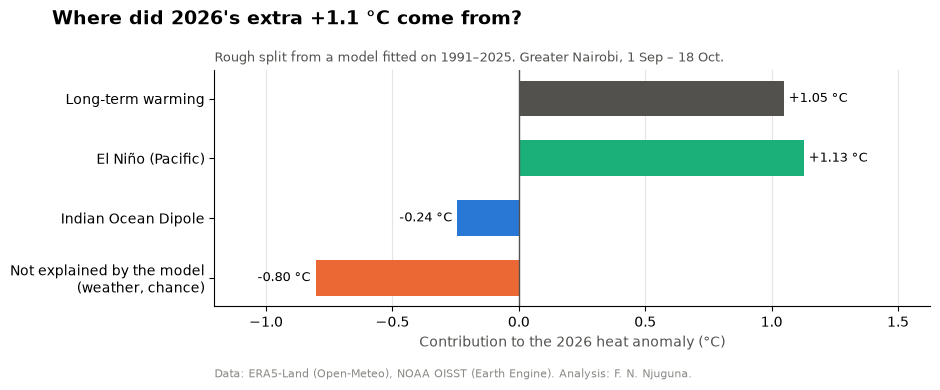

Long-term warming                                1.05
El Niño (Pacific)                                1.13
Indian Ocean Dipole                             -0.24
Not explained by the model\n(weather, chance)   -0.80
dtype: float64

In [67]:
x26 = yr.loc[THIS_YEAR]
parts = {
    "Long-term warming": hc["years_since_2005"] * x26["years_since_2005"],
    "El Niño (Pacific)": hc["nino34"] * x26["nino34"],
    "Indian Ocean Dipole": hc["iod"] * x26["iod"],
}
parts["Not explained by the model\n(weather, chance)"] = x26["anomaly"] - sum(parts.values()) - hc["const"]
parts_s = pd.Series(parts)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ypos = np.arange(len(parts_s))[::-1]
ax.barh(ypos, parts_s.values, color=[COL_NORMAL, COL_ELNINO[2015], COL_ELNINO[1997], COL_2026], height=0.6)
for yp, v in zip(ypos, parts_s.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), yp, f"{v:+.2f} °C", va="center", ha="left" if v >= 0 else "right", fontsize=9.5)
ax.set_yticks(ypos, parts_s.index)
ax.axvline(0, color="#52514e", lw=1)
ax.grid(axis="x", color="#e6e5e1"); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.set_xlim(min(0, parts_s.min()) - 0.4, max(0, parts_s.max()) + 0.5)
ax.set_xlabel("Contribution to the 2026 heat anomaly (°C)", color="#52514e")
titles(fig, ax, f"Where did {THIS_YEAR}'s extra {x26['anomaly']:+.1f} °C come from?",
       f"Rough split from a model fitted on {FIRST_YEAR}–{THIS_YEAR - 1}. Greater Nairobi, 1 Sep – {LAST_DATE:%d %b}.",
       "Data: ERA5-Land (Open-Meteo), NOAA OISST (Earth Engine). Analysis: F. N. Njuguna.", credit_y=-0.3)
fig.tight_layout(); fig.savefig(OUT / "chart7_heat_breakdown.png", dpi=200, bbox_inches="tight"); plt.show()
parts_s.round(2)

---
## Part 4 — Has the *ground* been hotter? (VIIRS satellite, per town)

### Air vs ground, in plain words

* **Air temperature** (Parts 1–3) is the shade thermometer, what your skin feels.
* **Land surface temperature (LST)** is how hot the *surface itself* is: roof, road, soil. A mabati roof in the sun can be 20 °C hotter than the air.

### Why VIIRS and not MODIS

We first used **MODIS on NASA's Terra satellite**, and it showed 2026's ground **about 9 °C cooler than normal on every single clear day**. That isn't weather. Terra is an old satellite whose orbit is no longer maintained, so it now passes over **earlier and earlier in the morning**: about 10:30 am originally, close to **9 am by 2025/26**. The ground is much cooler at 9 am than at 10:30, so Terra's recent readings drift steadily downward (Nairobi's Aug–Oct average fell from about 33–36 °C before 2023 to 29 °C in 2024, 28 °C in 2025 and 25 °C in 2026).

So we use **VIIRS on the Suomi NPP satellite** instead. It passes over at about **1:30 pm**, near the hottest part of the day, and has records from 2012, so the normal here is **2013–2025**.

**Limitation:** satellites can't see through clouds, so only clear days count. This is also the warm-up for notebook 02, where Landsat shows *which estates* heat up most.

### Step 4.1: Pull daily ground temperature for each town and the whole area

**What:** for every day from August to November, 2013–2026:
1. keep only **good-quality pixels**, using the quality flag VIIRS attaches to each pixel;
2. average over each town's 4 km circle and over the whole study area, noting **what share was cloud-free**;
3. convert to °C on your laptop (and check the units, in case the archive stores scaled whole numbers).

**Why record the cloud-free share?** If only a corner of a town is visible, its "average" is just that corner. We'll only keep days that are at least half clear.

**Sanity check printed at the end:** the yearly averages should stay roughly level from 2013 to 2026, without the steady slide we saw in Terra MODIS.

In [68]:
def with_retry(fn, *args):
    # Run an Earth Engine request; if EE says it's busy, wait and try again (up to 5 times)
    for attempt in range(5):
        try:
            return fn(*args)
        except ee.EEException as e:
            if "Too many" in str(e) or "429" in str(e):
                time.sleep(10 * (attempt + 1))
                continue
            raise
    raise RuntimeError("Earth Engine stayed busy. Wait a few minutes and run the cell again.")

viirs = ee.ImageCollection("NASA/VIIRS/002/VNP21A1D")
LST_FIRST_YEAR = 2013
today = ee.Date(dt.date.today().isoformat())
recent = viirs.filterDate(today.advance(-120, "day"), today)
if recent.size().getInfo():
    print("Newest VIIRS image:", ee.Date(recent.aggregate_max("system:time_start")).format("YYYY-MM-dd").getInfo())
else:
    print("No VIIRS images in the last 120 days; past years still work.")

REDUCER = ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True)

def lst_day(img):
    good = img.select("QC").bitwiseAnd(3).lte(1)        # bits 0-1: 0 = good, 1 = other quality
    raw = img.select("LST_1KM")
    lst = raw.updateMask(good).rename("lst")             # Kelvin (converted to °C below)
    total = raw.unmask(0).rename("total")
    date = img.date().format("YYYY-MM-dd")
    fc = lst.addBands(total).reduceRegions(areas_fc, REDUCER, 1000)
    return fc.map(lambda f: f.set({
        "date": date,
        "lst": ee.Algorithms.If(f.get("lst_mean"), f.get("lst_mean"), -999)}))

def lst_year(year):
    col = viirs.filterDate(f"{year}-{SEASON_START}", f"{year}-{SEASON_END}")
    fc = col.map(lst_day).flatten()
    rows = fc.reduceColumns(ee.Reducer.toList(5), ["name", "date", "lst", "lst_count", "total_count"]).get("list").getInfo()
    return pd.DataFrame(rows, columns=["name", "date", "lst", "clear_px", "total_px"])

cache = OUT / "viirs_lst_daily.csv"
if cache.exists() and dt.date.fromtimestamp(cache.stat().st_mtime) == dt.date.today():
    modis_raw = pd.read_csv(cache)
else:
    parts = []
    for y in range(LST_FIRST_YEAR, THIS_YEAR + 1):
        print(y, end=" ")
        parts.append(with_retry(lst_year, y))
    modis_raw = pd.concat(parts, ignore_index=True)
    modis_raw["clear_share"] = modis_raw.clear_px / modis_raw.total_px
    # Units: Kelvin → °C. If the archive stores scaled whole numbers (~15,000), apply the 0.02 scale first.
    ok = modis_raw.lst > -100
    if modis_raw.loc[ok, "lst"].median() > 1000:
        modis_raw.loc[ok, "lst"] *= 0.02
    modis_raw.loc[ok, "lst"] -= 273.15
    modis_raw.to_csv(cache, index=False)
print(f"\n{len(modis_raw):,} area-days fetched")

# Sanity check: yearly Aug–Oct average of clear days, whole study area (should NOT slide steadily downward)
_chk = modis_raw[(modis_raw.name == "Greater Nairobi") & (modis_raw.lst > -100) & (modis_raw.clear_share >= 0.5)].copy()
_chk["date"] = pd.to_datetime(_chk["date"])
_chk = _chk[_chk.date.dt.month.isin([8, 9, 10])]
print(_chk.groupby(_chk.date.dt.year)["lst"].agg(["mean", "count"]).round(1).T)


Newest VIIRS image: 2026-10-11
2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025 2026 
11,403 area-days fetched
date   2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  \
mean   39.7  38.8  40.0  39.8  42.1  37.5  38.5  38.8  40.6  42.0  39.7  37.1   
count  36.0  38.0  43.0  42.0  35.0  39.0  32.0  31.0  29.0  35.0  44.0  37.0   

date   2025  2026  
mean   37.8  37.6  
count  32.0  30.0  


### Step 4.2: Compare 2026's ground temperature with normal

**What:**
* keep days that were at least half cloud-free;
* build a normal per area from **2013–2025** (VIIRS records start in 2012, so the official 1991–2020 isn't possible here);
* compute 2026's average anomaly on its clear days since 1 September, per town;
* chart the whole study area, with 2026 as **dots** (one per clear day) so we don't pretend to know cloudy days.

**Why smooth the normal over 15 days?** Each date only has a few clear days across 23 years, so the raw normal is jumpy. A 15-day running average gives a fair "typical for this time of year".

,clear_days,anomaly_C,share_above_normal
area,,,
Kiambu,15,0.46,0.47
Thika,12,-0.28,0.50
Ongata Rongai,13,-0.90,0.38
Greater Nairobi,16,-1.39,0.31
Nairobi CBD,16,-1.88,0.31
Kitengela,13,-2.01,0.31
Ngong,18,-2.18,0.33


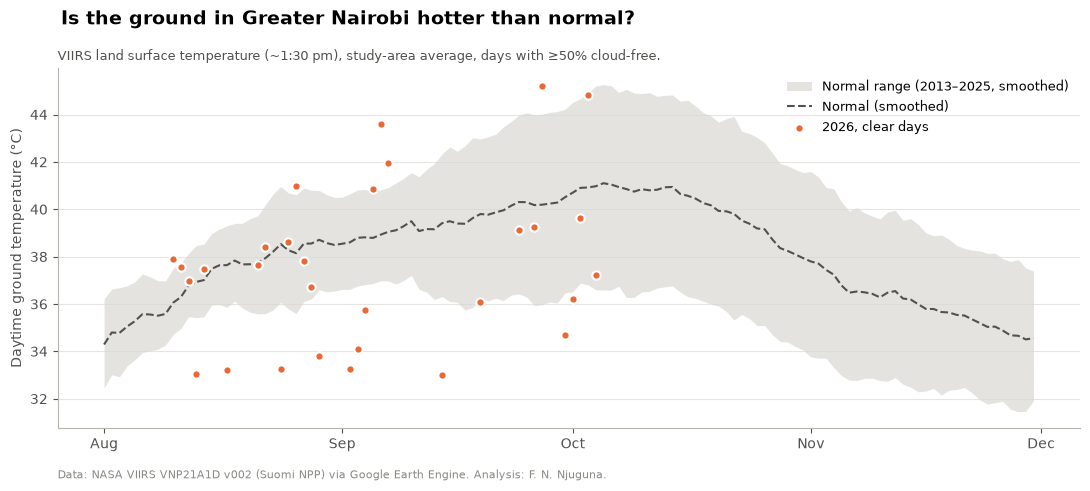

In [69]:
MODIS_BASELINE = (2013, 2025)      # name kept so later steps work; the data are VIIRS
lst = modis_raw[(modis_raw.lst > -100) & (modis_raw.clear_share >= 0.5)].copy()
lst["date"] = pd.to_datetime(lst["date"])
lst["year"] = lst.date.dt.year
lst["md"] = lst.date.dt.strftime("%m-%d")
lst["plotdate"] = pd.to_datetime("2000-" + lst["md"])

full_md = pd.date_range(f"2000-{SEASON_START}", f"2000-{SEASON_END}").strftime("%m-%d")
def smooth_normal(d):
    b = d[d.year.between(*MODIS_BASELINE)].groupby("md")["lst"]
    c = pd.DataFrame({"normal": b.mean(), "p10": b.quantile(0.1), "p90": b.quantile(0.9)}).reindex(full_md)
    c = c.rolling(15, center=True, min_periods=5).mean().reset_index(names="md")
    c["plotdate"] = pd.to_datetime("2000-" + c["md"])
    return c

lst_rows, lst_clims = [], {}
for name, d in lst.groupby("name"):
    c = smooth_normal(d); lst_clims[name] = c
    t = d[(d.year == THIS_YEAR) & (d.md >= FOCUS_START)].merge(c[["md", "normal"]], on="md")
    lst_rows.append({"area": name, "clear_days": len(t),
                     "anomaly_C": (t.lst - t.normal).mean() if len(t) else np.nan,
                     "share_above_normal": (t.lst > t.normal).mean() if len(t) else np.nan})
lst_table = pd.DataFrame(lst_rows).set_index("area").sort_values("anomaly_C", ascending=False).round(2)
display(lst_table)
lst_table.to_csv(OUT / "table_ground_temperature_2026.csv")

mc, md26 = lst_clims["Greater Nairobi"], lst[(lst.name == "Greater Nairobi") & (lst.year == THIS_YEAR)]
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(mc.plotdate, mc.p10, mc.p90, color=COL_BAND, alpha=0.7, lw=0,
                label=f"Normal range ({MODIS_BASELINE[0]}–{MODIS_BASELINE[1]}, smoothed)")
ax.plot(mc.plotdate, mc.normal, color=COL_NORMAL, ls="--", lw=1.5, label="Normal (smoothed)")
ax.scatter(md26.plotdate, md26.lst, s=36, color=COL_2026, edgecolor="white", linewidth=1.5, zorder=3, label=f"{THIS_YEAR}, clear days")
style_axes(ax)
ax.set_ylabel("Daytime ground temperature (°C)", color="#52514e")
titles(fig, ax, "Is the ground in Greater Nairobi hotter than normal?",
       "VIIRS land surface temperature (~1:30 pm), study-area average, days with ≥50% cloud-free.",
       "Data: NASA VIIRS VNP21A1D v002 (Suomi NPP) via Google Earth Engine. Analysis: F. N. Njuguna.")
ax.legend(frameon=False, fontsize=9, loc="upper right")
fig.tight_layout(); fig.savefig(OUT / "chart8_ground_temperature.png", dpi=200, bbox_inches="tight"); plt.show()

### What the ground data showed, and why we don't use it as evidence

**Result:** on the few clear days since 1 September (about 16), VIIRS shows Greater Nairobi's ground slightly *below* its 2013–2025 normal, with towns split both ways.

**Why we leave it out of the Week 1 conclusions:**
* **Too few clear days.** Clouds hide the ground on most days, so the 2026 figure rests on a handful of readings.
* **Ground and air don't move together year to year here.** Across 2013–2026, hot-air years and hot-ground years barely line up (correlation about zero). 2024–2026 had some of the hottest air on record, yet the ground read 2–3 °C cooler than 2013–2023.
* **Two possible reasons, which we can't separate:** (1) real: ground temperature depends heavily on how green and moist the land is, and the very wet 2024 long rains left greener, cooler ground; (2) technical: a small change in the satellite record.

**What we say instead:** *"Satellite surface temperature showed no clear signal this season."* Satellite heat data is used properly in notebook 02, where it compares **places with each other on the same dates**. That comparison isn't affected by year-to-year sensor or wetness shifts.

---
## Part 5 — Double-check the rain dates with CHIRPS

### Why

ERA5 is a model, and in East Africa it's known to produce too many light drizzly days. That could make our onset dates (and so Suspect 1) wrong. **CHIRPS** is built differently: satellite rain estimates corrected with real rain-gauge readings. If both agree on onset dates for past years, our rain story holds up.

### Step 5.1: Get CHIRPS rainfall for the study area, 1991 onwards

**What:** the daily average rainfall over the study area, September to December, for every year CHIRPS fully covers.
**Why only up to last year?** The Earth Engine copy hasn't reached this season yet. Re-run this part in the new year to add 2026.

In [70]:
chirps = ee.ImageCollection("UCSB-CHC/CHIRPS/V3/DAILY_RNL").select("precipitation")
CHIRPS_LAST = pd.to_datetime(ee.Date(chirps.filterDate(f"{THIS_YEAR - 1}-01-01", f"{THIS_YEAR + 1}-01-01")
                                     .aggregate_max("system:time_start")).format("YYYY-MM-dd").getInfo())
print(f"CHIRPS v3 in Earth Engine currently ends on {CHIRPS_LAST:%d %b %Y}")
last_full = CHIRPS_LAST.year if CHIRPS_LAST.strftime("%m-%d") == "12-31" else CHIRPS_LAST.year - 1

def chirps_year(year):
    col = chirps.filterDate(f"{year}-09-01", f"{year + 1}-01-01")
    fc = col.map(lambda img: ee.Feature(None, {
        "date": img.date().format("YYYY-MM-dd"),
        "rain": img.reduceRegion(ee.Reducer.mean(), metro_geom, 5566).get("precipitation")}))
    rows = fc.reduceColumns(ee.Reducer.toList(2), ["date", "rain"]).get("list").getInfo()
    return pd.DataFrame(rows, columns=["date", "rain"])

cache = OUT / "chirps_daily.csv"
if cache.exists():
    chirps_df = pd.read_csv(cache)
else:
    chirps_df = pd.concat([with_retry(chirps_year, y) for y in range(FIRST_YEAR, last_full + 1)], ignore_index=True)
    chirps_df.to_csv(cache, index=False)
print(f"CHIRPS days: {len(chirps_df):,}")

CHIRPS v3 in Earth Engine currently ends on 30 Sep 2026
CHIRPS days: 4,270


### Step 5.2: Same rule, two datasets: do they agree?

**What:** run the identical onset rule on CHIRPS and compare the dates with ERA5's, year by year.
**Why:** a typical difference of about a week or less means our rain dates are trustworthy. If they disagree a lot, say so in the brief and lean on CHIRPS for past years.

**Also printed:** the normal onset date by CHIRPS. If it's later than our latest 2026 date too, then "the rains aren't late yet" holds on both datasets.

In [71]:
chirps_df["date"] = pd.to_datetime(chirps_df["date"])
chirps_df["year"] = chirps_df.date.dt.year
chirps_df["md"] = chirps_df.date.dt.strftime("%m-%d")
onsets_chirps = onsets_by_year(chirps_df)
compare = onsets[["onset", "onset_doy"]].join(onsets_chirps[["onset", "onset_doy"]],
                                              lsuffix="_era5", rsuffix="_chirps", how="inner")
compare["days_apart"] = compare.onset_doy_era5 - compare.onset_doy_chirps
typical_gap = compare["days_apart"].abs().median()
print(f"Years compared: {compare.days_apart.notna().sum()}. Typical ERA5 vs CHIRPS difference: {typical_gap:.0f} days")
compare.to_csv(OUT / "table_onset_era5_vs_chirps.csv")
chirps_normal_doy = int(onsets_chirps.loc[BASELINE[0]:BASELINE[1], "onset_doy"].median())
chirps_normal = pd.Timestamp(f"{THIS_YEAR}-01-01") + pd.Timedelta(days=chirps_normal_doy - 1)
exact = (compare.days_apart.abs() <= 3).sum()
print(f"Within 3 days of each other: {exact} years. Normal onset by CHIRPS: around {chirps_normal:%d %B} (ERA5: {median_onset:%d %B}).")

Years compared: 26. Typical ERA5 vs CHIRPS difference: 14 days
Within 3 days of each other: 9 years. Normal onset by CHIRPS: around 02 November (ERA5: 06 November).


---
## Part 6 — The verdict, in plain sentences

**What:** the notebook writes its own findings from the numbers above, suspect by suspect, plus an overall answer.
**Why:** no re-typing numbers (or typos) when you write the brief and the post. If you re-run next week, the sentences update themselves.

**Read them critically before using them.** Does each one match its chart? Is anything surprising? Surprises are either a great story or a bug, so check which before you post.

In [72]:
L = []
a26 = anom.loc[THIS_YEAR]
L.append(f"THE CASE: Between 1 September and {LAST_DATE:%d %B} {THIS_YEAR}, Greater Nairobi's average afternoon "
         f"temperature was {a26['value']:.1f} °C, {a26['anomaly']:+.1f} °C compared with the {BASELINE[0]}–{BASELINE[1]} "
         f"normal: rank {int(a26['rank_hottest'])} of {n_years} years since {FIRST_YEAR} (1 = hottest). "
         f"The hottest town relative to normal was {town_table.index[0]} ({town_table.anomaly_C.iloc[0]:+.1f} °C).")

o26 = onsets.loc[THIS_YEAR]
rain_txt = (f"the short rains began around {o26.onset:%d %B} ({o26.status}), {int(o26.onset_doy) - median_doy:+d} days vs normal"
            if pd.notna(o26.onset) else f"the short rains had not properly started by {LAST_DATE:%d %B} (normal onset: about {median_onset:%d %B})")
L.append(f"SUSPECT 1, late rains and clear skies: {so_far:.0f} mm of rain fell since 1 September ({so_far / normal_so_far:.0%} of normal), "
         f"and {rain_txt}. Sunshine reaching the ground was {sun_anom.loc[THIS_YEAR, 'anomaly']:+.1f} MJ/m² per day vs normal. "
         f"Across {FIRST_YEAR}–{THIS_YEAR - 1}, sunshine explains {sun_model.rsquared:.0%} of the ups and downs in Nairobi's heat, "
         f"and this season's extra sunshine accounts for roughly {sun_part:+.1f} °C.")

L.append(f"SUSPECT 2, El Niño: the Pacific (Niño 3.4) was {x26['nino34']:+.1f} °C warmer than the tropical average (relative index, comparable to NOAA's). Across {len(fit)} years, "
         f"El Niño warmth shows {verdict_dir(hp['nino34'], hc['nino34'])} with Nairobi's Sep–Oct heat ({hc['nino34']:+.2f} °C per degree), "
         f"and {verdict_dir(op['nino34'], oc['nino34'], 'later rains', 'earlier rains')} with when the rains start ({oc['nino34']:+.1f} days per degree).")
L.append(f"SUSPECT 3, the Indian Ocean Dipole: the IOD was {x26['iod']:+.1f} °C. It shows {verdict_dir(hp['iod'], hc['iod'])} with heat "
         f"and {verdict_dir(op['iod'], oc['iod'], 'later rains', 'earlier rains')} with rain onset ({oc['iod']:+.1f} days per degree).")
L.append(f"SUSPECT 4, long-term warming: {hc['years_since_2005'] * 10:+.2f} °C per decade, {verdict(hp['years_since_2005'])}. "
         f"On its own, it puts {THIS_YEAR} about {parts_s.iloc[0]:+.1f} °C above the baseline average.")

biggest = parts_s.abs().idxmax().split("\n")[0]
L.append(f"OVERALL: of {THIS_YEAR}'s {a26['anomaly']:+.1f} °C, the model suggests roughly "
         + "; ".join(f"{k.split(chr(10))[0]}: {v:+.1f} °C" for k, v in parts_s.items())
         + f". The biggest single piece is: {biggest}.")
try:
    L.append("GROUND CHECK (not used as evidence): satellite surface temperature (VIIRS) showed no clear signal this season. "
             "It rests on few clear days, and year to year it doesn't track air temperature here (see the note after Step 4.2).")
    L.append(f"RAIN CHECK: ERA5 and CHIRPS onset dates typically differ by {typical_gap:.0f} days.")
except (NameError, KeyError):
    pass

findings = "\n\n".join(L)
print(findings)
(OUT / "findings.txt").write_text(findings, encoding="utf-8")

THE CASE: Between 1 September and 18 October 2026, Greater Nairobi's average afternoon temperature was 25.7 °C, +1.1 °C compared with the 1991–2020 normal: rank 5 of 36 years since 1991 (1 = hottest). The hottest town relative to normal was Ongata Rongai (+1.7 °C).

SUSPECT 1, late rains and clear skies: 30 mm of rain fell since 1 September (86% of normal), and the short rains had not properly started by 18 October (normal onset: about 06 November). Sunshine reaching the ground was +0.1 MJ/m² per day vs normal. Across 1991–2025, sunshine explains 68% of the ups and downs in Nairobi's heat, and this season's extra sunshine accounts for roughly +0.0 °C.

SUSPECT 2, El Niño: the Pacific (Niño 3.4) was +2.1 °C warmer than the tropical average (relative index, comparable to NOAA's). Across 35 years, El Niño warmth shows a clear link (hotter) with Nairobi's Sep–Oct heat (+0.54 °C per degree), and no clear link with when the rains start (+3.0 days per degree).

SUSPECT 3, the Indian Ocean Dip

1694

### How to turn the verdict into your story

Read the sentences above against this chain:

**El Niño / IOD → warmer tropical air, and changes in when the rains come → heat now, rain later**

* If **Suspect 1** (late rains, clear skies) is weak but **El Niño** shows a clear link, the story is: **"It's not that the rains are late. El Niño warms the air first and brings the rain later, on top of a warming baseline."** That directly answers the public confusion.
* If El Niño shows *no clear link* but Suspect 1 is strong, the story is about the delayed rains instead.
* Either way, the long-term warming piece explains why every hot spell now feels hotter than it used to.

Don't decide the headline until you've checked each sentence against its chart.

---
## What this notebook can and can't claim

Put these in your brief's "Limitations" box. They make the work *more* credible.

1. **Association, not laboratory proof.** The tests show which suspects line up with 35 years of evidence, and roughly how much. Formal attribution needs climate-model experiments.
2. **35 years is a small sample.** A "no clear link" means *the data can't confirm it*, not *it's impossible*.
3. **Reanalysis isn't a thermometer.** ERA5 can be a degree or so off actual stations, but the error is steady, so year-to-year comparisons hold. A strong extra step is to check against Kenya Met station data (Dagoretti, JKIA, Wilson, Thika) if you can get it.
4. **Towns vs grid squares.** ERA5-Land squares are about 10 km wide. Close towns (e.g. Ongata Rongai and Ngong) may partly share squares, so town differences are indicative, not street-level. Week 2 handles that.
5. **El Niño is measured with a relative index** (Pacific minus the tropical average), like NOAA since 2026. With the traditional index, recent El Niños look stronger than they are.
8. **The warming trend (~0.4–0.5 °C per decade here) is on the high side** of published Kenyan figures. Reanalysis trends can run high; station data would firm it up.
9. **El Niño's effect on air temperature lags the ocean** by a few months, so Sep–Oct may not show this El Niño's full effect. Re-run in January.
6. **Satellites see only clear days.** We dropped Terra MODIS because its drifting orbit (overpass near 9 am by 2025/26) makes recent years read several degrees too cool. VIIRS (Suomi NPP) is used instead, from 2013. Even so, satellite ground temperature doesn't track air temperature year to year here, so it is reported as "no clear signal" rather than used as evidence.
7. **One onset rule among several.** The CHIRPS cross-check shows how sensitive the dates are.

## What's saved in `outputs/`

| File | What it shows |
|---|---|
| `chart1_air_temperature.png` | **Headline:** 2026 vs normal and El Niño years |
| `chart2_anomaly_by_year.png` | Every year ranked, same weeks |
| `chart3_towns.png` | Each town's 2026 anomaly |
| `chart4_cumulative_rain.png` | Rain since 1 September |
| `chart5_sunshine.png` | Solar energy vs normal (Suspect 1) |
| `chart6_elnino_test.png` | Do El Niño years make Nairobi hotter? |
| `chart7_heat_breakdown.png` | **Answer chart:** where 2026's extra heat came from |
| `chart8_ground_temperature.png` | VIIRS ground temperature vs normal |
| `table_*.csv`, `findings.txt` | The numbers and sentences behind everything |

**Next (Week 2):** Landsat 30 m surface temperature and Sentinel-2 greenery by ward and town, to show *where* the heat collects.